# DC4 source catalog: creation and simulation checks

**Branch: `SourceCatTest`.** Runtime COSIpy changes are on `DC4-SourceCat`; both analysis notebooks live here.

Create **one flat folder containing ordinary astromodels YAML and FITS model files**.
Only this notebook needs the `cosi-sim` source library and its light curves. The
fitting notebook needs the resulting folder, observation/background, spacecraft
history and detector response. It does not read light curves or a JSON recipe.

The catalog has **51 entries: 32 point sources and 19 extended sources**. GRBs,
MGFs and the short magnetar burst are excluded. Quiet/flare states of 4C+21.35
and low/high states of 3C 454.3 are summed as physical spectra into one entry
per AGN. Repeating components are averaged. CO nova's three emission components
remain separate entries.

**Convention:** MEGAlib's `.Flux` for a file light curve is its mean over the
complete light-curve span. Normalize that profile to unit mean, integrate over
the reference observation, and apply this factor once to `.Flux`. Do not apply
the active-time fraction a second time. There is no parallel-chunk correction
in this static product. It is intended for matching steady/averaged simulations,
including future simulations with the chunk-normalization issue corrected.


In [1]:
from pathlib import Path
import tempfile
import shutil
import numpy as np
import pandas as pd
import astropy.units as u
from astropy.io import fits
from IPython.display import display
from cosipy.spacecraftfile import SpacecraftHistory
# Creation tools exist on SourceCatTest only; fitting does not import these.
import sys

# Run from this directory or any subdirectory of the COSIpy checkout.
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'cosipy'/'__init__.py').is_file())
tutorial = repo/'docs/tutorials/spectral_fits/source_catalog'
if str(tutorial) not in sys.path:
    sys.path.insert(0, str(tutorial))
from dc4_catalog_tools.generation import create_dc4_source_catalog, load_source_catalog

# Configure these two input locations on your machine. They are creation inputs.
SOURCE_LIBRARY = Path.home()/'Software/cosi-sim/cosi_sim/Source_Library'
DC4_ROOT = Path.home()/'Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files'
ORIENTATION = DC4_ROOT/'DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori'
# Shared model folder, independent of the checked-out branch.
OUTPUT = DC4_ROOT/'dc4_source_catalog'
# Overwrite only this creator's named output products; unrelated files are not deleted.
OVERWRITE = True


21:20:03 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=67606;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=28099;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=293876;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=590146;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

21:20:04 WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=272420;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=258597;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

21:20:04 INFO      Starting 3ML!                                                                     ]8;id=316650;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=994600;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

WARNING   WARNINGs here are NOT errors                                                      ]8;id=409539;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=482236;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

WARNING   but are inform you about optional packages that can be installed                  ]8;id=296438;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=938735;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#46\46]8;;\

... (2 outputs left out)

WARNING   Multinest minimizer not available                                           ]8;id=239239;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=609000;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1218\1218]8;;\

WARNING   PyGMO is not available                                                      ]8;id=10685;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py\minimization.py]8;;\:]8;id=725332;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/minimization.py#1228\1228]8;;\

WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=176684;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=34363;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

21:20:05 WARNING   No fermitools installed                                              ]8;id=875129;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=396801;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

In [2]:
# Use the full observation, including its existing quality/livetime treatment.
# No target-dependent pointing cut or extra GTI enters the catalog average.
history = SpacecraftHistory.open(ORIENTATION)
start, stop = float(history.tstart.unix), float(history.tstop.unix)
print(f'Reference observation: {history.tstart.isot} to {history.tstop.isot} UTC')
print(f'Elapsed time: {stop-start:,.0f} s; livetime: {history.cumulative_livetime().to_value(u.s):,.0f} s')


Reference observation: 2028-03-01T01:35:00.000 to 2028-06-01T10:14:15.000 UTC
Elapsed time: 7,979,955 s; livetime: 6,579,555 s


## Generate the models

Read positions/morphologies, spectral shapes and absolute `.Flux` values from
the original `.source` definitions. No event counts are used to set amplitudes.
Preserve each tabulated spectrum's effective MEGAlib interpolation (linear or
log-log, including the zero-value fallback) and native energy samples. Fit-time
integration includes these samples inside every incident-energy response bin.

The 11 coupled spatial/energy maps are converted to Galactic RING HEALPix NSIDE 8
FITS templates. NSIDE 64 is used only internally to average the input map;
no second set of spatial files is distributed. Narrow line integrals are
preserved even when a broad response bin contains the line.

Input hashes, reference times and conversion details are retained in notebook
output. Spectral FITS contain only two physical columns and their standard units;
interpolation is an ordinary model property in the YAML. No custom provenance
headers are needed. The YAML has the normal astromodels model structure.


In [3]:
yaml_path, component_rows = create_dc4_source_catalog(
    SOURCE_LIBRARY, OUTPUT, start, stop, overwrite=OVERWRITE,
)
catalog = load_source_catalog(yaml_path)
assert (len(catalog.point_sources), len(catalog.extended_sources)) == (32, 19)
assert not catalog.free_parameters
print(f'Saved {len(catalog.sources)} frozen entries: {yaml_path}')
print(f'{len(list(OUTPUT.glob("*.fits")))} FITS model assets, all beside the YAML')
# These rows describe original simulation components; grouped AGN states
# are combined into one final spectral FITS, rather than fitted twice.
averages = pd.DataFrame(component_rows)
columns = ['source', 'component', 'time factor', 'light curve', 'model file']
display(averages.loc[averages['light curve'].ne(''), columns].reset_index(drop=True))
# Also retain hashes for analytic YAML-only components, which have no own FITS header.
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(averages[['component', 'source sha256', 'light curve sha256']])


51 frozen entries; relocated catalog: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/dc4_source_catalog/dc4_catalog.yaml
36 FITS model assets, all beside the YAML


,source,component,time factor,light curve,model file
0,crab,Crab_P1,1.000000,Crab_P1_lc.dat,crab_peak1_spec.fits
1,crab,Crab_Brg,1.000000,Crab_Brg_lc.dat,crab_bridge_spec.fits
2,crab,Crab_P2,1.000000,Crab_P2_lc.dat,crab_peak2_spec.fits
3,maxi_j1820,MAXIJ1820_0p1-0p4,1.000000,MAXIJ1820_LC.dat,maxi_j1820_maxij1820_0p1__3b17.fits
4,maxi_j1820,MAXIJ1820_0p4-10,1.000000,MAXIJ1820_LC.dat,maxi_j1820_maxij1820_0p4__9235.fits
5,maxi_j1348,MAXIJ1348_0p1-0p4,1.000000,MAXIJ1348_LC.dat,maxi_j1348_maxij1348_0p1__5262.fits
6,maxi_j1348,MAXIJ1348_0p4-10,1.000000,MAXIJ1348_LC.dat,maxi_j1348_maxij1348_0p4__498b.fits
7,psr_b1259,PSRB1259,1.000000,PSRB1259_lc.dat,psr_b1259_spec.fits
8,one_rxs_j170849,1RXSJ170849,1.000000,1RXSJ170849_magnetar_lightcurve.dat.gz,one_rxs_j170849_spec.fits
9,generic_magnetar,magnetar2,1.000000,magnetar2_lightcurve.dat.gz,generic_magnetar_spec.fits


,component,source sha256,light curve sha256
0,cygX1_hard_01-04,855521980ccefbbe58c61b4a3ffa107859e4a41381da55a289466a0558e1c45b,
1,cygX1_hard_04-10,855521980ccefbbe58c61b4a3ffa107859e4a41381da55a289466a0558e1c45b,
2,Crab_Nebula,ded12f121d9ab547009b255144b11cb943b843223228bef771b086b8e9a1e78f,
3,Crab_P1,ded12f121d9ab547009b255144b11cb943b843223228bef771b086b8e9a1e78f,072ce9a5fec3d00f25537a8495cadd19c72db717429505c524f791a34d4ca35f
4,Crab_Brg,ded12f121d9ab547009b255144b11cb943b843223228bef771b086b8e9a1e78f,dbcff3b62e2865b51644b0c38fd540e0479be79c5a6f2d574126511059d9ff3c
5,Crab_P2,ded12f121d9ab547009b255144b11cb943b843223228bef771b086b8e9a1e78f,6086a2b2085df996b455bd0c17d94953080aa3ddf37167cae77a0c459e37307c
6,1E1740_compow,bcea70d7f1b9e226954f0fba8f9038b4d25c8a65ee6cc8c69fc0dde2f02ec837,
7,GRS1758,c3e1f618d813192f55878fe43c1e1d11607ca5952e4a9eae9295da7a6e1e8408,
8,CenA,86d3b6bb22747abbf4c3e67c7ef7b22ce24c26559b82cc00f3854977b06f39f6,
9,4C71p07,e3b3072d5a484978d5600955f4f72b5400fbba98c5299fbf0c6d10e6625549ae,


## Validate the simple FITS tables and portability

FITS tables contain source flux/intensity models, **not measured event counts**.
They are a documented COSI model format, not OGIP PHA files or XSPEC `atable`.
FITS is suitable for distribution; HEASARC product acceptance still requires
agreement on the release format. This catalog is for total-intensity continuum
analysis, not a replacement for a phase/state-dependent polarization model.


In [4]:
assets = sorted(OUTPUT.glob('*.fits'))
referenced = set()
for source in catalog.sources.values():
    spatial = getattr(source, 'spatial_shape', None)
    if hasattr(spatial, '_fitsfile'):
        referenced.add(Path(spatial._fitsfile).name)
    for component in source.components.values():
        if hasattr(component.shape, 'fits_file'):
            referenced.add(Path(component.shape.fits_file.value).name)
assert referenced == {p.name for p in assets}, 'Missing or unreferenced model file'
for path in assets:
    with fits.open(path, checksum=True) as hdul:
        hdul.verify('exception')
        assert all(h.verify_checksum() in (1, 2) and h.verify_datasum() in (1, 2) for h in hdul)
assert not list(OUTPUT.glob('*.dat')) and not list(OUTPUT.glob('*.json'))
assert not any(p.is_dir() for p in OUTPUT.iterdir())

# Move a complete copy and resolve assets relative to the copied YAML.
# No paths to the source library or original output folder may be needed.
with tempfile.TemporaryDirectory() as temporary:
    moved = Path(temporary)/'catalog'
    shutil.copytree(OUTPUT, moved)
    relocated = load_source_catalog(moved/yaml_path.name)
    assert len(relocated.sources) == 51 and not relocated.free_parameters
    assert str(OUTPUT.resolve()) not in str(relocated.to_dict())
print('FITS structure, all asset references, and relocated loading: PASS')


FITS structure, all asset references, and relocated loading: PASS


Distribute `dc4_source_catalog/` as a unit. The consumer does not need this
notebook's source library, `.source` files or light curves. A different fitting
time interval uses this same static catalog as starting models, with matching
event/background cuts and a newly constructed response. For an actual flare,
refit the target's normalization and spectral shape; its full-observation mean
is not a prediction of its flare flux.


## Compare to the actual simulated DC4 source files

Compare **absolute detector counts**, first summed over energy and then in the
native ten measured-energy bins. Source fluxes are fixed by the simulation
definitions; these comparisons never fit or rescale them to match event counts.
Both predictions and events cover the full orientation interval with the same
existing quality selection, and no extra pointing cut. No background events
enter these source-by-source comparisons.

Start with the two steady references below. Add variable or extended sources
with `COMPARE_SOURCES`, or use `list(catalog.sources)` for all 51. Grouped AGN
states are compared to the **sum of their two event files**. Crab's event file
is compared to its four components together. The explicit mapping is in
`dc4_catalog_tools/simulation_files.py`; change its root or override individual
entries for your corrected simulations. No older comparison cache is imported.

**Legacy DC4 caveat:** these paths currently select the old chunked simulations.
Their differences are diagnostics, not a test of corrected chunks. Even with
corrected chunk normalization, a static catalog can differ from variable-source
events because the average discards time/pointing correlations. Use your planned
steady/mean mock for a controlled test of this static catalog.

In [5]:
import matplotlib.pyplot as plt
from histpy import Axes, HealpixAxis
from cosipy.response import FullDetectorResponse, ExtendedSourceResponse
from dc4_catalog_tools.comparison import compare_catalog_sources, file_hash
from dc4_catalog_tools.simulation_files import SIMULATION_FILES

SOURCE_EVENT_ROOT = DC4_ROOT/'DC4_Sources'  # Point this at the corrected files when ready.
source_event_files = {name:[SOURCE_EVENT_ROOT/p for p in paths]
                      for name,paths in SIMULATION_FILES.items()}
# Override paths here if your new simulations have different filenames:
# source_event_files['ngc4151'] = [Path('/path/to/new_NGC4151.fits.gz')]
COMPARE_SOURCES = ['cena', 'ngc4151']
# Examples: 'crab', 'four_c_21p35', 'three_c_454p3', 'maxi_j1348',
#           'co_nova_continuum', 'positrons_26al_line'.
RESPONSE = DC4_ROOT/'ResponseContinuum.o3.e100_10000.b10log.s10396905069491.m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5'
# Only needed when comparing extended sources. Supply a verified full-observation
# response, or leave None to build one. The first full build can occupy ~14 GB.
FULL_EXTENDED_RESPONSE = None
WORK = tutorial/'work'
WORK.mkdir(exist_ok=True)
for name in COMPARE_SOURCES:
    if name not in catalog.sources:
        raise KeyError(f'No catalog source: {name}')
    for path in source_event_files[name]:
        if not path.is_file():
            raise FileNotFoundError(path)

In [6]:
# One common history/response for every static source. No light-curve weighting.
detector_response = FullDetectorResponse.open(RESPONSE)
def get_full_extended_response():
    # Called only for an extended source whose numerical counts are not cached.
    if FULL_EXTENDED_RESPONSE is None:
        return detector_response.get_extended_source_response(
            history, nside_image=8,
            nside_scatt_map=2*detector_response.axes['PsiChi'].nside,
        )
    else:
        return ExtendedSourceResponse.open(FULL_EXTENDED_RESPONSE)

# Invalidate numerical caches when the model bundle, orientation, detector
# response, or simulation files change. Caches live outside the model folder.
model_inputs = [yaml_path, *sorted(OUTPUT.glob('*.fits')), ORIENTATION, RESPONSE]
if FULL_EXTENDED_RESPONSE is not None:
    model_inputs.append(Path(FULL_EXTENDED_RESPONSE))
model_key = ''.join(file_hash(path) for path in model_inputs)
energy_edges, comparisons = compare_catalog_sources(
    catalog, source_event_files, COMPARE_SOURCES, detector_response, history,
    WORK/'simulation_comparisons', model_cache_key=model_key,
    extended_response_factory=get_full_extended_response,
)

[1/2] cena


[2/2] ngc4151


### Total counts and model / simulation ratios

A ratio of one indicates agreement. A Poisson counting error is shown for the
simulation; it does not include finite response statistics or model uncertainty.
Missing/zero simulation counts are reported without dividing by zero.

,model_counts,simulated_counts,model_over_simulation
source,,,
cena,118380.032001,113576,1.042298
ngc4151,78720.992282,72697,1.082864


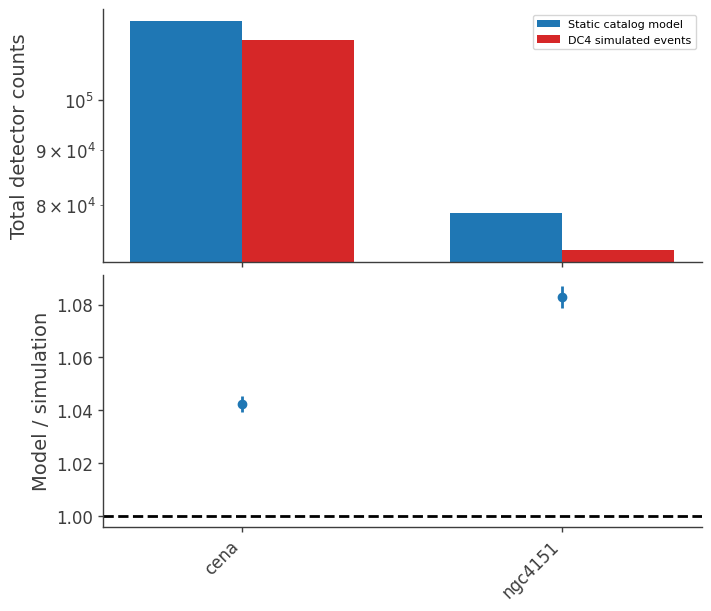

In [7]:
rows=[]
energy_rows=[]
for name, counts in comparisons.items():
    predicted, simulated = counts['model'], counts['simulation']
    model_total, simulation_total = float(predicted.sum()), int(simulated.sum())
    rows.append(dict(source=name, model_counts=model_total,
                     simulated_counts=simulation_total,
                     model_over_simulation=model_total/simulation_total if simulation_total else np.nan))
    for lo, hi, model_bin, simulation_bin in zip(energy_edges[:-1], energy_edges[1:],predicted,simulated):
        energy_rows.append(dict(source=name, E_min_keV=lo, E_max_keV=hi,
                                model_counts=model_bin, simulated_counts=int(simulation_bin),
                                model_over_simulation=model_bin/simulation_bin if simulation_bin else np.nan))
count_comparison=pd.DataFrame(rows).set_index('source')
display(count_comparison)
count_comparison.to_csv(WORK/'dc4_catalog_total_counts.csv')
pd.DataFrame(energy_rows).to_csv(WORK/'dc4_catalog_energy_counts.csv',index=False)

fig, axes=plt.subplots(2,1,figsize=(max(7,.5*len(rows)),6),sharex=True,layout='constrained')
x=np.arange(len(rows));width=.35
axes[0].bar(x-width/2,count_comparison['model_counts'],width,label='Static catalog model',color='tab:blue')
axes[0].bar(x+width/2,count_comparison['simulated_counts'],width,label='DC4 simulated events',color='tab:red')
axes[0].set(yscale='log',ylabel='Total detector counts')
axes[0].legend()
ratio=count_comparison['model_over_simulation'].to_numpy()
n=count_comparison['simulated_counts'].to_numpy()
ratio_error=np.divide(ratio,np.sqrt(n),out=np.full_like(ratio,np.nan),where=n>0)
axes[1].errorbar(x,ratio,yerr=ratio_error,fmt='o',color='tab:blue')
axes[1].axhline(1,color='black',ls='--')
axes[1].set(ylabel='Model / simulation')
axes[1].set_xticks(x,count_comparison.index,rotation=45,ha='right')
fig.savefig(WORK/'dc4_catalog_total_counts.pdf',facecolor='white',bbox_inches='tight')
plt.show()

### Energy-resolved count spectra

These are **measured-energy count spectra**, with the physical spectral models
folded through the response before comparison. A photon-flux curve cannot be
directly compared to an event energy histogram. Zero-count bins remain in the
count table but have no finite model/simulation ratio.

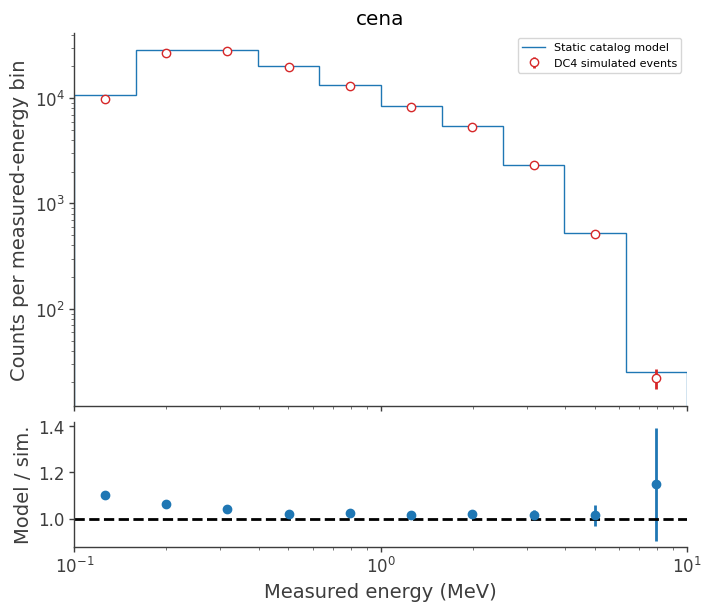

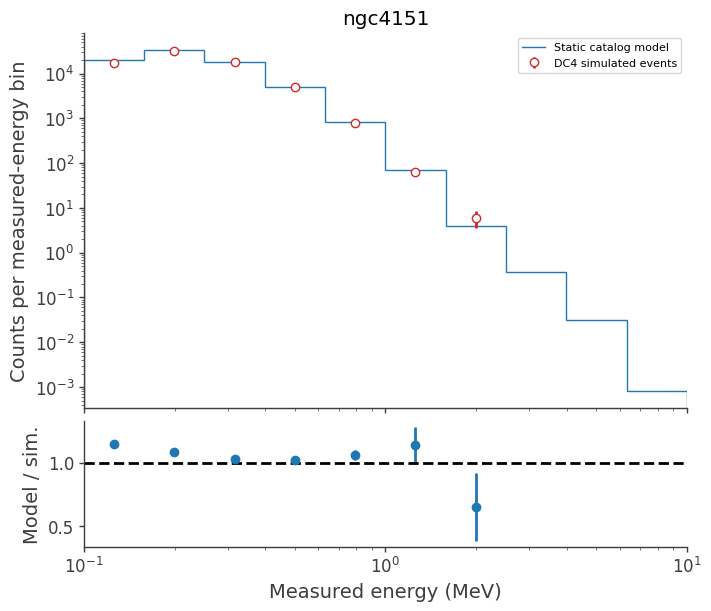

In [8]:
for name, counts in comparisons.items():
    predicted, simulated=counts['model'],counts['simulation']
    centers=np.sqrt(energy_edges[:-1]*energy_edges[1:])/1000.
    fig,axes=plt.subplots(2,1,figsize=(7,6),sharex=True,
                         gridspec_kw={'height_ratios':[3,1]},layout='constrained')
    axes[0].stairs(predicted,energy_edges/1000.,color='tab:blue',label='Static catalog model')
    axes[0].errorbar(centers,simulated,yerr=np.sqrt(simulated),fmt='o',
                     color='tab:red',markerfacecolor='white',label='DC4 simulated events')
    axes[0].set(yscale='log',ylabel='Counts per measured-energy bin',title=name)
    axes[0].legend()
    ratio=np.divide(predicted,simulated,out=np.full_like(predicted,np.nan),where=simulated>0)
    error=np.divide(ratio,np.sqrt(simulated),out=np.full_like(ratio,np.nan),where=simulated>0)
    axes[1].errorbar(centers,ratio,yerr=error,fmt='o',color='tab:blue')
    axes[1].axhline(1,color='black',ls='--')
    axes[1].set(xscale='log',xlim=(energy_edges[0]/1000.,energy_edges[-1]/1000.),
                xlabel='Measured energy (MeV)',ylabel='Model / sim.')
    fig.savefig(WORK/f'dc4_catalog_energy_{name}.pdf',facecolor='white',bbox_inches='tight')
    plt.show()